# 1단계 — 행렬·미분에서 신경망 한 번 학습까지

**질문:** 예측이 틀렸을 때 어느 가중치를 어떻게 바꿔야 할까?

작은 행렬과 수치 미분 → 고정 신경망의 순전파·손실 → 연쇄 법칙 → 기울기 검산 →
한 번 갱신 → 반복 학습·Momentum 순서로 실행한다. 뒤의 **선형대수 연결**에서는
같은 행렬 곱이 공간 변환·Power Iteration·SVD에 쓰이는 모습을 확인한다.
수식 유도와 손계산 표는 계산 근거로 함께 읽는다.

다음은 [확률과 손실](probability_loss.ipynb)이다. 두 노트북은 변수를 공유하지 않아
각각 새 커널에서 실행할 수 있다. A2-1에서 `uv sync --locked`를 실행한 뒤 `.venv`를
커널로 선택하고 **커널 재시작 후 전체 실행**한다. 이 노트북은 입력 이미지를 읽지만
기존 `outputs/`를 읽거나 덮어쓰지 않는다. 직접 그린 그림과 계산 출력은 노트북에 남는다.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# notebooks/에서 열든 프로젝트 루트에서 열든 src를 import할 수 있게 한다.
# Path.cwd()는 현재 작업 폴더, .name은 그 마지막 폴더 이름, .parent는 한 단계 위 폴더다.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# sys.path는 import할 모듈을 찾는 폴더 목록이다. 맨 앞(0번)에 A2-1 폴더를 넣어 `from src...`가 동작하게 한다.
sys.path.insert(0, str(ROOT))
np.random.seed(42)
# 배열 출력을 소수점 6자리로, 1e-05 같은 지수 표기 대신 일반 소수로 보여 준다(계산 값은 바뀌지 않는다).
np.set_printoptions(precision=6, suppress=True)

## 준비 — 행렬 한 행과 미분 한 좌표

`@`는 곱한 뒤 더하는 행렬 곱이다. `*`는 같은 위치끼리 곱한다.
신경망에서는 행이 도착 뉴런, 열이 출발 입력이다. 먼저 한 행을 손으로 계산하고 전체와 대조한다.

In [2]:
matrix = np.array([[0.1, 0.2], [0.3, 0.4]])
input_vector = np.array([1., 0.])
first_neuron = matrix[0, 0] * input_vector[0] + matrix[0, 1] * input_vector[1]
all_neurons = matrix @ input_vector
print("첫 뉴런 손계산:", first_neuron)
print("전체 행렬 곱:", all_neurons, "shape:", all_neurons.shape)
print("원소별 곱은 합하지 않음:\n", matrix * input_vector)
np.testing.assert_allclose(all_neurons, [first_neuron, 0.3])

첫 뉴런 손계산: 0.1
전체 행렬 곱: [0.1 0.3] shape: (2,)
원소별 곱은 합하지 않음:
 [[0.1 0. ]
 [0.3 0. ]]


미분은 입력을 조금 바꿨을 때 출력이 얼마나 변하는지 잰다. 중심차분은
`(f(x+h) - f(x-h)) / (2h)`다. 아래에서 함수를 값처럼 전달하는 문법을 먼저 경험한다.
이후 가중치 한 칸의 손실 변화도 같은 방법으로 검산한다.

In [3]:
from src import calculus as calc

def square(value):
    return value ** 2

location = 3.0
h = 1e-5
f_plus = square(location + h)
f_minus = square(location - h)
slope = (f_plus - f_minus) / (2 * h)
print("f(x+h), f(x-h), 기울기:", f_plus, f_minus, slope)
np.testing.assert_allclose(slope, 6.0, atol=1e-8)
np.testing.assert_allclose(slope, calc.numerical_derivative(square, location, h))

f(x+h), f(x-h), 기울기: 9.0000600001 8.999940000099999 6.000000000039306


### 여러 좌표의 미분과 등고선

`x²+y²`의 점 `[1,2]`에서 좌표별로 중심차분하면 `[2,4]`가 된다.
같은 원 위에서 각도만 ±δ 움직인 두 점의 차이로 접선을 구하면 기울기와 거의 수직이다.
그림에서 등고선은 같은 함수값이고 화살표는 증가 방향이다. 축 단위 길이를 같게 읽자.

좌표별 미분 / 등고선 접선과의 cos: [2. 4.] 0.0


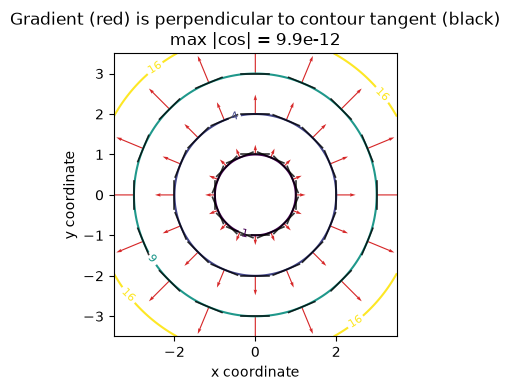

In [4]:
def bowl(point):
    return point[0]**2 + point[1]**2

point = np.array([1.,2.])
gradient = calc.numerical_gradient(bowl,point)
radius = np.linalg.norm(point)
angle = np.arctan2(point[1],point[0])
delta = 1e-4
neighbor_plus = radius*np.array([np.cos(angle+delta),np.sin(angle+delta)])
neighbor_minus = radius*np.array([np.cos(angle-delta),np.sin(angle-delta)])
tangent = neighbor_plus-neighbor_minus
cosine = np.dot(gradient,tangent)/(np.linalg.norm(gradient)*np.linalg.norm(tangent))
print("좌표별 미분 / 등고선 접선과의 cos:",gradient,cosine)
np.testing.assert_allclose(gradient,[2.,4.],atol=1e-8)
assert abs(cosine)<1e-8
fig,ax = plt.subplots(figsize=(5,4))
calc.plot_gradient_field(bowl,ax=ax)
ax.set(xlabel="x coordinate",ylabel="y coordinate")
fig.tight_layout()
plt.show()

## 1. 구조와 표기

```
x(2) ──W1(2×2), b1(2)──▶ z1(2) ──σ──▶ a1(2) ──W2(2), b2──▶ z2 ──σ──▶ ŷ ──BCE──▶ L
```

| 기호 | 의미 | shape |
| --- | --- | --- |
| $x$ | 입력 | (2,) |
| $W_1$ | 은닉층 가중치. $W_1[i,j]$ = 입력 $j$ → 은닉 $i$ | (2, 2) |
| $b_1$ | 은닉층 편향 | (2,) |
| $z_1, a_1$ | 은닉층 선형 결과, 활성화 결과 | (2,) |
| $W_2$ | 출력층 가중치 | (2,) |
| $b_2$ | 출력층 편향 | 스칼라 |
| $z_2, \hat y$ | 출력층 선형 결과, 예측 확률 | 스칼라 |
| $L$ | 손실 | 스칼라 |

**규칙:** 어떤 값에 대한 기울기 $\partial L/\partial(\cdot)$의 shape은 그 값의 shape과 같다. 가중치를 $W \leftarrow W - \eta\,\partial L/\partial W$로 갱신하려면 shape이 같아야 하기 때문이다. 역전파 중 shape이 맞지 않으면 유도가 틀렸다는 신호다.

## 2. 순전파 수식

$$
\begin{aligned}
z_1 &= W_1 x + b_1 && (2,) = (2,2)\,(2,) + (2,) \\
a_1 &= \sigma(z_1), \quad \sigma(z) = \frac{1}{1+e^{-z}} && (2,) \\
z_2 &= W_2 \cdot a_1 + b_2 && () = (2,)\cdot(2,) + () \\
\hat y &= \sigma(z_2) && () \\
L &= -\big[\,y \log \hat y + (1-y)\log(1-\hat y)\,\big] && ()
\end{aligned}
$$

원소별로 쓰면 $z_{1,i} = \sum_j W_1[i,j]\,x_j + b_{1,i}$이다.

### 고정 예제와 순전파 손계산

| 값 | 설정 |
| --- | --- |
| $x$ | [1, 0] |
| $W_1$ | [[0.1, 0.2], [0.3, 0.4]] |
| $b_1$ | [0, 0] |
| $W_2$ | [0.5, 0.6] |
| $b_2$ | 0 |
| 활성화 / 손실 | Sigmoid / BCE |
| $y$ | 1 |

이 예제는 정답 $y=1$인 한 관측을 사용한다. 손으로 따라 할 수 있도록 곱셈·덧셈을 모두 적었다. $e^{-z}$ 값만 계산기를 사용하고, 표는 소수점 6자리 표시이며, 코드의 중간 계산은 반올림하지 않는다. 표시된 값끼리 다시 곱하면 마지막 자릿수가 달라질 수 있다.

### 4-1. 순전파

| 단계 | 계산 | 결과 | shape |
| --- | --- | --- | --- |
| $z_1$ | $[0.1\cdot1 + 0.2\cdot0 + 0,\ \ 0.3\cdot1 + 0.4\cdot0 + 0]$ | **[0.1, 0.3]** | (2,) |
| $e^{-z_1}$ | $[e^{-0.1},\ e^{-0.3}]$ | [0.904837, 0.740818] | (2,) |
| $a_1$ | $[1/1.904837,\ 1/1.740818]$ | **[0.524979, 0.574443]** | (2,) |
| $z_2$ | $0.5\cdot0.524979 + 0.6\cdot0.574443 + 0 = 0.262490 + 0.344666$ | **0.607155** | () |
| $e^{-z_2}$ | $e^{-0.607155}$ | 0.544899 | () |
| $\hat y$ | $1/1.544899$ | **0.647292** | () |
| $L$ | $-\log 0.647292$ | 0.434958 | () |

### 순전파 실행 1 — 선형 결합

입력과 가중치를 준비하고 `z1`까지만 실행한다. 편향은 모든 연결의 합에 마지막으로 더한다.
아래 고정 값은 위 손계산과 같은 실험이며, 초기화용 난수는 쓰지 않는다.

In [5]:
x = np.array([1.0, 0.0])
W1 = np.array([[0.1, 0.2], [0.3, 0.4]])
b1 = np.zeros(2)
W2 = np.array([0.5, 0.6])
b2 = 0.0
y = 1.0

def sigmoid(value):
    return 1 / (1 + np.exp(-value))

z1 = W1 @ x + b1
print("W1 / x / z1의 shape:", W1.shape, x.shape, z1.shape)
print("z1:", z1)

W1 / x / z1의 shape: (2, 2) (2,) (2,)
z1: [0.1 0.3]


### 순전파 실행 2 — 활성화·예측·손실

은닉 활성화 `a1`은 입력을 변환한 값이고, 최종 `y_pred`는 정답이 1일 확률로 해석한다.
BCE는 실제 정답에 부여한 확률이 낮을수록 커진다. 자연로그를 쓰며 여기서는 관측 한 개의 손실이다.

In [6]:
a1 = sigmoid(z1)
z2 = W2 @ a1 + b2
y_pred = sigmoid(z2)
L = -(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
print("a1:", a1, "shape:", a1.shape)
print("z2 / 예측 확률 / BCE:", z2, y_pred, L)
np.testing.assert_allclose([z2, y_pred, L], [0.607155, 0.647292, 0.434958], atol=1e-6)

a1: [0.524979 0.574443] shape: (2,)
z2 / 예측 확률 / BCE: 0.6071551038264654 0.6472915699946178 0.4349584368514606


## 3. 역전파 수식 유도

역전파는 손실 $L$에서 출발해 **그래프를 거꾸로** 따라가며 연쇄 법칙 $\dfrac{\partial L}{\partial u} = \dfrac{\partial L}{\partial v}\cdot\dfrac{\partial v}{\partial u}$를 반복한다. 각 단계는 "위에서 내려온 기울기 × 이 노드의 국소 미분"이다.

### 3-1. 출력 $\partial L/\partial \hat y$ — shape ()

$$
\frac{\partial L}{\partial \hat y} = -\frac{y}{\hat y} + \frac{1-y}{1-\hat y}
$$

### 3-2. 시그모이드 미분

$$
\sigma'(z) = \frac{e^{-z}}{(1+e^{-z})^2} = \sigma(z)\,\big(1-\sigma(z)\big)
$$

### 3-3. $\partial L/\partial z_2$ — shape () ← 체크포인트

$$
\frac{\partial L}{\partial z_2} = \frac{\partial L}{\partial \hat y}\,\hat y(1-\hat y)
= \Big(-\frac{y}{\hat y} + \frac{1-y}{1-\hat y}\Big)\hat y(1-\hat y)
= -y(1-\hat y) + (1-y)\hat y = \hat y - y
$$

Sigmoid와 BCE를 함께 쓰면 분모가 약분되어 **예측 − 정답**만 남는다. 출력층의 기울기가 오차 그 자체가 된다.

### 3-4. 출력층 파라미터

$z_2 = \sum_i W_{2,i}\,a_{1,i} + b_2$이므로 $\partial z_2/\partial W_{2,i} = a_{1,i}$, $\partial z_2/\partial b_2 = 1$.

$$
\frac{\partial L}{\partial W_2} = \frac{\partial L}{\partial z_2}\,a_1 \quad (2,), \qquad
\frac{\partial L}{\partial b_2} = \frac{\partial L}{\partial z_2} \quad ()
$$

### 3-5. 은닉층으로 전달 $\partial L/\partial a_1$ — shape (2,)

$\partial z_2/\partial a_{1,i} = W_{2,i}$이므로

$$
\frac{\partial L}{\partial a_1} = \frac{\partial L}{\partial z_2}\,W_2
$$

### 3-6. 은닉층 활성화 통과 $\partial L/\partial z_1$ — shape (2,) ← 체크포인트

$a_{1,i}$는 $z_{1,i}$에만 의존하므로 원소별 곱(⊙)이다.

$$
\frac{\partial L}{\partial z_1} = \frac{\partial L}{\partial a_1} \odot \sigma'(z_1) = \frac{\partial L}{\partial a_1} \odot a_1 \odot (1-a_1)
$$

### 3-7. 은닉층 파라미터 $\partial L/\partial W_1$ — shape (2, 2)

$\partial z_{1,i}/\partial W_1[i,j] = x_j$이므로 $\dfrac{\partial L}{\partial W_1[i,j]} = \dfrac{\partial L}{\partial z_{1,i}}\,x_j$, 즉 외적이다.

$$
\frac{\partial L}{\partial W_1} = \frac{\partial L}{\partial z_1}\,x^{\top} = \mathrm{outer}\Big(\frac{\partial L}{\partial z_1},\,x\Big) \quad (2,1)(1,2) = (2,2), \qquad
\frac{\partial L}{\partial b_1} = \frac{\partial L}{\partial z_1}
$$

### 정리

| 단계 | 식 | shape |
| --- | --- | --- |
| $\partial L/\partial \hat y$ | $-y/\hat y + (1-y)/(1-\hat y)$ | () |
| $\partial L/\partial z_2$ | $\hat y - y$ | () |
| $\partial L/\partial W_2$ | $\partial L/\partial z_2 \cdot a_1$ | (2,) |
| $\partial L/\partial a_1$ | $\partial L/\partial z_2 \cdot W_2$ | (2,) |
| $\partial L/\partial z_1$ | $\partial L/\partial a_1 \odot a_1(1-a_1)$ | (2,) |
| $\partial L/\partial W_1$ | $\mathrm{outer}(\partial L/\partial z_1, x)$ | (2, 2) |

### 손계산의 역전파 체크포인트



| 단계 | 계산 | 결과 | shape |
| --- | --- | --- | --- |
| $\partial L/\partial \hat y$ | $-1/0.647292$ | **−1.544899** | () |
| $\partial L/\partial z_2$ ✔ | $0.647292 - 1$ (검산: $-1.544899 \times 0.647292 \times 0.352708 = -0.352708$) | **−0.352708** | () |
| $\partial L/\partial W_2$ | $-0.352708 \times [0.524979,\ 0.574443]$ | **[−0.185165, −0.202611]** | (2,) |
| $\partial L/\partial b_2$ | $= \partial L/\partial z_2$ | −0.352708 | () |
| $\partial L/\partial a_1$ | $-0.352708 \times [0.5,\ 0.6]$ | **[−0.176354, −0.211625]** | (2,) |
| $\sigma'(z_1)$ | $[0.524979 \times 0.475021,\ 0.574443 \times 0.425557]$ | [0.249376, 0.244458] | (2,) |
| $\partial L/\partial z_1$ ✔ | $[-0.176354 \times 0.249376,\ -0.211625 \times 0.244458]$ | **[−0.043979, −0.051734]** | (2,) |
| $\partial L/\partial W_1$ | $\begin{bmatrix}-0.043979\cdot1 & -0.043979\cdot0\\ -0.051733\cdot1 & -0.051733\cdot0\end{bmatrix}$ | **[[−0.043979, 0], [−0.051734, 0]]** | (2, 2) |
| $\partial L/\partial b_1$ | $= \partial L/\partial z_1$ | [−0.043979, −0.051734] | (2,) |

✔ 표시는 중간 체크포인트다. $\partial L/\partial z_2$가 맞으면 출력층이, $\partial L/\partial z_1$이 맞으면 은닉층까지의 연쇄가 맞다.

**관찰.** $x_2 = 0$이므로 $W_1$의 두 번째 열 기울기는 0이다. 이번 입력에서 쓰이지 않은 연결은 손실에 영향을 주지 않아 갱신되지 않는다.

### 역전파 실행 1 — 출력층에서 은닉 활성화까지

먼저 `dL_dy_pred × y_pred × (1-y_pred)`를 구하고 `y_pred-y`와 대조한다.
기울기가 음수라는 것은 이 위치에서 해당 값을 증가시키면 손실이 작아진다는 국소 정보다.

In [7]:
dL_dy_pred = -y / y_pred + (1 - y) / (1 - y_pred)
dL_dz2 = dL_dy_pred * y_pred * (1 - y_pred)
dL_dW2 = dL_dz2 * a1
dL_db2 = dL_dz2
dL_da1 = dL_dz2 * W2
print("dL/dy_pred:", dL_dy_pred)
print("연쇄 법칙 / 예측-정답:", dL_dz2, y_pred-y)
print("dL/dW2:", dL_dW2, "dL/da1:", dL_da1)
np.testing.assert_allclose(dL_dz2, y_pred-y)

dL/dy_pred: -1.5448988467566709
연쇄 법칙 / 예측-정답: -0.35270843000538216 -0.3527084300053822
dL/dW2: [-0.185165 -0.202611] dL/da1: [-0.176354 -0.211625]


### 역전파 실행 2 — 은닉 활성화에서 첫 가중치까지

은닉 뉴런마다 시그모이드의 국소 미분을 곱한다. `outer`는 두 벡터의 모든 조합을 곱해
행렬을 만든다. 첫 가중치 `[0,0]` 하나를 직접 계산해 외적의 위치와 대조한다.

In [8]:
local_sigmoid_gradient = a1 * (1-a1)
dL_dz1 = dL_da1 * local_sigmoid_gradient
first_weight_gradient = dL_dz1[0] * x[0]
dL_dW1 = np.outer(dL_dz1, x)
dL_db1 = dL_dz1.copy()
print("은닉층 국소 미분:", local_sigmoid_gradient)
print("dL/dz1:", dL_dz1)
print("dL/dW1:\n", dL_dW1, "shape:", dL_dW1.shape)
np.testing.assert_allclose(dL_dW1[0,0], first_weight_gradient)
np.testing.assert_allclose(dL_dW1[:,1], 0.)
assert dL_dW1.shape == W1.shape and dL_db1.shape == b1.shape
numpy_values = {"z1": z1, "a1": a1, "z2": z2, "y_pred": y_pred,
                "dL_dy_pred": dL_dy_pred, "dL_dz2": dL_dz2, "dL_dW2": dL_dW2,
                "dL_da1": dL_da1, "dL_dz1": dL_dz1, "dL_dW1": dL_dW1}

은닉층 국소 미분: [0.249376 0.244458]
dL/dz1: [-0.043979 -0.051734]
dL/dW1:
 [[-0.043979 -0.      ]
 [-0.051734 -0.      ]] shape: (2, 2)


In [9]:
# 손계산 결과를 소수점 4자리로 반올림해 적는다 (위 표의 굵은 값).
# {"이름": 값} 사전(dict)이다. [[...], [...]]는 2행 2열 행렬을 리스트로 적은 것이다.
hand = {
    "z1": [0.1000, 0.3000],
    "a1": [0.5250, 0.5744],
    "z2": 0.6072,
    "y_pred": 0.6473,
    "dL_dy_pred": -1.5449,
    "dL_dz2": -0.3527,
    "dL_dW2": [-0.1852, -0.2026],
    "dL_da1": [-0.1764, -0.2116],
    "dL_dz1": [-0.0440, -0.0517],
    "dL_dW1": [[-0.0440, 0.0000], [-0.0517, 0.0000]],
}

## 4. 손계산과 소수점 4자리 비교

In [10]:
all_match = True
for name, hand_value in hand.items():
    rounded = np.round(numpy_values[name], 4) + 0.0   # + 0.0: -0.0을 0.0으로 맞춘다
    # array_equal은 shape과 모든 값이 정확히 같을 때만 True다.
    match = np.array_equal(rounded, np.array(hand_value))
    # a &= b는 a = a & b. 하나라도 False가 나오면 all_match는 끝까지 False로 남는다.
    all_match &= match
    print(f"{name:11s} 손계산={str(hand_value):32s} NumPy={str(rounded.tolist()):32s} {'일치' if match else '불일치'}")
# assert 조건: 조건이 거짓이면 이 자리에서 오류를 내고 멈춘다. 확인이 실패했는데 다음 셀로 넘어가지 않게 한다.
assert all_match
print("\n손계산 결과와 NumPy 결과가 소수점 4자리까지 모두 일치한다.")

z1          손계산=[0.1, 0.3]                       NumPy=[0.1, 0.3]                       일치
a1          손계산=[0.525, 0.5744]                  NumPy=[0.525, 0.5744]                  일치
z2          손계산=0.6072                           NumPy=0.6072                           일치
y_pred      손계산=0.6473                           NumPy=0.6473                           일치
dL_dy_pred  손계산=-1.5449                          NumPy=-1.5449                          일치
dL_dz2      손계산=-0.3527                          NumPy=-0.3527                          일치
dL_dW2      손계산=[-0.1852, -0.2026]               NumPy=[-0.1852, -0.2026]               일치
dL_da1      손계산=[-0.1764, -0.2116]               NumPy=[-0.1764, -0.2116]               일치
dL_dz1      손계산=[-0.044, -0.0517]                NumPy=[-0.044, -0.0517]                일치
dL_dW1      손계산=[[-0.044, 0.0], [-0.0517, 0.0]]  NumPy=[[-0.044, 0.0], [-0.0517, 0.0]]  일치

손계산 결과와 NumPy 결과가 소수점 4자리까지 모두 일치한다.


## 5. 모듈 구현과 수치 미분으로 교차 검증

해석적으로 유도한 기울기가 맞다면, 가중치를 아주 조금 움직였을 때 손실 변화량(중심차분)과 같아야 한다. 이 검증은 유도 과정과 무관한 독립적인 확인이다.

In [11]:
from src.neural_net import example_network
from src.calculus import numerical_gradient

net, x_ex, y_ex = example_network()
cache = net.forward(x_ex, y_ex)
grads = net.backward(cache, y_ex)
# cache는 순전파의 반환 사전이며 객체 안의 가중치와는 별개다.
for name, value in cache.items():
    print(name, "shape=", np.shape(value), "value=", value)
for name in ("z1", "a1", "z2", "y_pred"):
    np.testing.assert_allclose(cache[name], numpy_values[name])
np.testing.assert_allclose(cache["loss"], L)
for name, value in grads.items():
    print(name, "shape=", np.shape(value))
manual_gradients = {"dL_dy_pred": dL_dy_pred, "dL_dz2": dL_dz2,
                    "dL_dW2": dL_dW2, "dL_db2": dL_db2, "dL_da1": dL_da1,
                    "dL_dz1": dL_dz1, "dL_dW1": dL_dW1, "dL_db1": dL_db1}
for name, value in manual_gradients.items():
    np.testing.assert_allclose(grads[name], value)
print("직접 계산과 모듈의 모든 순전파·역전파 결과 일치")

x shape= (2,) value= [1. 0.]
z1 shape= (2,) value= [0.1 0.3]
a1 shape= (2,) value= [0.524979 0.574443]
z2 shape= () value= 0.6071551038264654
y_pred shape= () value= 0.6472915699946178
loss shape= () value= 0.4349584368514606
dL_dy_pred shape= ()
dL_dz2 shape= ()
dL_dW2 shape= (2,)
dL_db2 shape= ()
dL_da1 shape= (2,)
dL_dz1 shape= (2,)
dL_dW1 shape= (2, 2)
dL_db1 shape= (2,)
직접 계산과 모듈의 모든 순전파·역전파 결과 일치


### 가중치 한 칸만 ±h 움직여 검산하기

`loss_with`는 임시 신경망을 만들어 계산하므로 원래 가중치를 바꾸지 않는다.
중심차분은 역전파 식을 쓰지 않아서 독립적인 대조가 된다. 같은 순전파에서 얻은
cache·기울기·가중치를 한 묶음으로 사용하고, 갱신 후에는 다시 순전파한다.

In [12]:
h = 1e-5
W1_before_check = net.W1.copy()
W1_plus = net.W1.copy()
W1_minus = net.W1.copy()
W1_plus[0,0] += h
W1_minus[0,0] -= h
loss_plus = net.loss_with(x_ex, y_ex, W1=W1_plus)
loss_minus = net.loss_with(x_ex, y_ex, W1=W1_minus)
numeric_one_weight = (loss_plus-loss_minus) / (2*h)
print("한 칸의 수치 미분 / 역전파:", numeric_one_weight, grads["dL_dW1"][0,0])
np.testing.assert_allclose(numeric_one_weight, grads["dL_dW1"][0,0], atol=1e-8)
np.testing.assert_array_equal(net.W1, W1_before_check)

def loss_for_W1(candidate):
    return net.loss_with(x_ex, y_ex, W1=candidate)

num_W1 = numerical_gradient(loss_for_W1, net.W1)
# 같은 기능을 반복할 때 lambda는 인자를 받아 손실 하나를 돌려주는 짧은 함수다.
num_W2 = numerical_gradient(lambda candidate: net.loss_with(x_ex, y_ex, W2=candidate), net.W2)
num_b1 = numerical_gradient(lambda candidate: net.loss_with(x_ex, y_ex, b1=candidate), net.b1)
num_b2 = numerical_gradient(lambda candidate: net.loss_with(x_ex, y_ex, b2=float(candidate)), np.array(net.b2))
numeric_gradients = {"dL_dW1": num_W1, "dL_dW2": num_W2, "dL_db1": num_b1, "dL_db2": num_b2}
errors = []
for name, value in numeric_gradients.items():
    error = np.max(np.abs(value-grads[name]))
    errors.append(error)
    print(name, "최대 절대 차이:", error)
    np.testing.assert_allclose(value, grads[name], atol=1e-8, rtol=0.)
print("전체 최대 차이:", max(errors))

한 칸의 수치 미분 / 역전파: -0.04397851580406619 -0.043978515808697
dL_dW1 최대 절대 차이: 1.0556548690754397e-11
dL_dW2 최대 절대 차이: 3.259587044723844e-12
dL_db1 최대 절대 차이: 1.0556548690754397e-11
dL_db2 최대 절대 차이: 7.178257988016412e-12
전체 최대 차이: 1.0556548690754397e-11


## 6. 첫 갱신을 먼저 보고 반복하기

정답이 1이고 현재 확률은 약 0.647이다. `새 값 = 이전 값 - 학습률 × 기울기`를
네 파라미터에 직접 적용한 뒤 클래스가 바꾸는 값과 비교한다.
아래 셀은 실행할 때마다 새 객체를 만들어 같은 초기 상태에서 시작한다.
`sgd_step()`의 반환값은 `None`이고 가중치는 객체 내부에서 바뀐다.

In [13]:
train_net, train_x, train_y = example_network()
eta = 0.5
before = train_net.forward(train_x, train_y)
train_grads = train_net.backward(before, train_y)
expected_W1 = train_net.W1 - eta*train_grads["dL_dW1"]
expected_b1 = train_net.b1 - eta*train_grads["dL_db1"]
expected_W2 = train_net.W2 - eta*train_grads["dL_dW2"]
expected_b2 = train_net.b2 - eta*train_grads["dL_db2"]
step_return = train_net.sgd_step(train_grads, eta)
after = train_net.forward(train_x, train_y)
print("갱신 반환값:", step_return)
print("첫 갱신의 W1:\n", train_net.W1)
print("첫 갱신의 W2:", train_net.W2)
print("예측 확률 전후:", before["y_pred"], after["y_pred"])
print("BCE 전후:", before["loss"], after["loss"])
for actual, expected in [(train_net.W1, expected_W1), (train_net.b1, expected_b1),
                         (train_net.W2, expected_W2), (train_net.b2, expected_b2)]:
    np.testing.assert_allclose(actual, expected)
assert step_return is None and after["loss"] < before["loss"]
np.testing.assert_allclose(train_net.W1[:,1], W1[:,1])

갱신 반환값: None
첫 갱신의 W1:
 [[0.121989 0.2     ]
 [0.325867 0.4     ]]
첫 갱신의 W2: [0.592582 0.701305]
예측 확률 전후: 0.6472915699946178 0.7121053369751515
BCE 전후: 0.4349584368514606 0.339529433323152


같은 관측을 20번 학습하면 어떨까? 매번 현재 가중치로 순전파·역전파를 새로 계산한다.
이 셀도 새 객체에서 시작하므로 반복 실행해도 20스텝의 결과다. 손실 감소는 이 한 관측의
학습 결과이며, 새로운 입력에 잘 맞는다는 일반화 검증은 아니다. 임의의 큰 학습률에서
매 스텝 손실이 감소한다는 보장도 없다.

20회 갱신 후 W2: [1.223906 1.391429]
처음 / 첫 갱신 / 20회 손실: 0.4349584368514606 0.339529433323152 0.047304013431341455


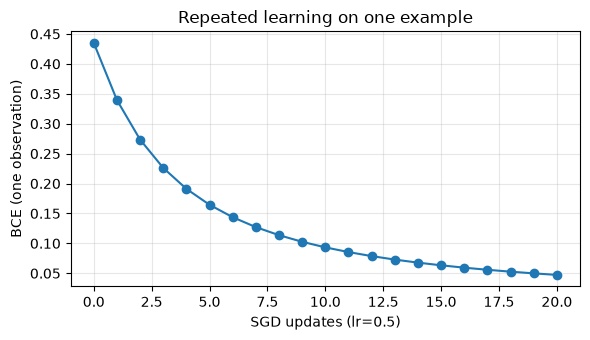

In [14]:
loop_net, loop_x, loop_y = example_network()
losses = [loop_net.forward(loop_x, loop_y)["loss"]]
for step in range(20):
    loop_cache = loop_net.forward(loop_x, loop_y)
    loop_grads = loop_net.backward(loop_cache, loop_y)
    loop_net.sgd_step(loop_grads, eta)
    losses.append(loop_net.forward(loop_x, loop_y)["loss"])
np.testing.assert_allclose(losses[:2], [before["loss"], after["loss"]])
print("20회 갱신 후 W2:", loop_net.W2)
print("처음 / 첫 갱신 / 20회 손실:", losses[0], losses[1], losses[-1])
fig, ax = plt.subplots(figsize=(6,3.5))
ax.plot(range(21), losses, "o-")
ax.set(xlabel="SGD updates (lr=0.5)", ylabel="BCE (one observation)", title="Repeated learning on one example")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 7. GD와 Momentum — 위치와 객체 상태를 분리하기

신경망의 수많은 가중치 대신 좌표 두 개를 움직여 보자. 함수는 `x²+10y²`,
기울기는 `[2x,20y]`다. Momentum은 `v = 0.9v + gradient`, `position -= lr*v`를 쓴다.
첫 스텝은 GD와 같지만 두 번째부터 과거 속도가 남는다. `step`은 새 위치를 반환하고
객체 안에서는 속도 `v`와 호출 수 `t`를 바꾼다.

In [15]:
from src import optimizer as opt

position = np.array([5.,5.])
velocity = np.zeros(2)
momentum = opt.Momentum(lr=0.01, beta=0.9)
print("첫 호출 전 상태:", momentum.t, momentum.v)
for step in range(1,3):
    position_before = position.copy()
    gradient = opt.elliptic_grad(position)
    velocity = 0.9*velocity + gradient
    manual_next = position - 0.01*velocity
    input_position = position
    position = momentum.step(input_position, gradient)
    print("step", step, "시작", position_before, "기울기", gradient,
          "속도", momentum.v, "다음 위치", position)
    np.testing.assert_allclose(position, manual_next)
    np.testing.assert_allclose(momentum.v, velocity)
    np.testing.assert_array_equal(input_position, position_before)
assert momentum.t == 2
momentum.reset()
assert momentum.t == 0 and momentum.v is None

첫 호출 전 상태: 0 None
step 1 시작 [5. 5.] 기울기 [ 10. 100.] 속도 [ 10. 100.] 다음 위치 [4.9 4. ]
step 2 시작 [4.9 4. ] 기울기 [ 9.8 80. ] 속도 [ 18.8 170. ] 다음 위치 [4.712 2.3  ]


### 같은 조건에서 경로를 비교하기

기존 실험과 같은 시작점 `(5,5)`, 100회, β=0.9를 쓴다. 작은 lr=0.01에서는 Momentum이
더 가까이 가지만 lr=0.09에서는 GD가 더 가깝다. **Momentum이 항상 빠르다**는 결론을
만들기 위해 조건을 고르지 말고 두 결과를 함께 설명하자. `optimize`는 시작할 때
객체 상태를 초기화하고 `(101,2)` 경로를 반환한다. 행 0이 시작점이다.

lr 0.01 경로 shape (101, 2) 최종 원점 거리 GD / Momentum 0.6630977794737659 0.025498770066137846
lr 0.09 경로 shape (101, 2) 최종 원점 거리 GD / Momentum 1.2075513101649619e-08 0.02543280932468792


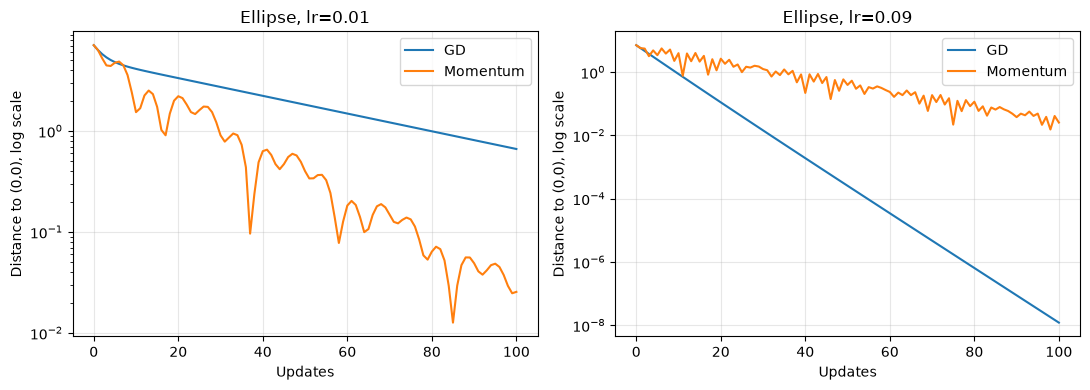

원형 함수 lr 0.1 100회 뒤 거리 1.4404019523870759e-09
원형 함수 lr 0.5 100회 뒤 거리 0.0
원형 함수 lr 1.0 100회 뒤 거리 7.0710678118654755
원형 함수 lr 1.1 100회 뒤 거리 585611513.88652


In [16]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax, learning_rate in zip(axes, [0.01,0.09]):
    gd_path = opt.optimize(opt.VanillaGD(learning_rate), opt.elliptic_grad, [5,5], 100)
    mom_path = opt.optimize(opt.Momentum(learning_rate,0.9), opt.elliptic_grad, [5,5], 100)
    print("lr", learning_rate, "경로 shape", gd_path.shape,
          "최종 원점 거리 GD / Momentum", np.linalg.norm(gd_path[-1]), np.linalg.norm(mom_path[-1]))
    ax.semilogy(np.linalg.norm(gd_path,axis=1), label="GD")
    ax.semilogy(np.linalg.norm(mom_path,axis=1), label="Momentum")
    ax.set(xlabel="Updates", ylabel="Distance to (0,0), log scale", title=f"Ellipse, lr={learning_rate}")
    ax.legend()
    ax.grid(alpha=0.3)
    assert gd_path.shape == mom_path.shape == (101,2)
fig.tight_layout()
plt.show()

# f=x²+y²에서는 다음 위치가 (1-2lr)배다. 같은 lr도 함수 곡률에 따라 다르게 작동한다.
for learning_rate in [0.1,0.5,1.0,1.1]:
    path = opt.optimize(opt.VanillaGD(learning_rate), opt.quadratic_grad, [5,5],100)
    expected = np.array([5.,5.])*(1-2*learning_rate)**100
    np.testing.assert_allclose(path[-1], expected, atol=1e-8)
    print("원형 함수 lr", learning_rate, "100회 뒤 거리", np.linalg.norm(path[-1]))

## 8. 선형대수 연결 — 공간 변환·반복·압축

이 절은 신경망의 `W @ x`와 같은 연산을 다른 대상에서 읽는 기본 실습이다.
첫 예제의 행·열 의미와 달리 아래 점 배열은 `(좌표 2개, 점 N개)`다.
열 하나가 점 하나다. 회전·스케일·전단은 모양을 바꾸지만 여기의 세 설정은 모두
면적을 보존한다. 면적비가 항상 1인 것은 아니므로 det=5인 행렬도 대조한다.

점 배열의 shape: (2, 100)
일반 행렬 det / 면적비: 5.0 5.0


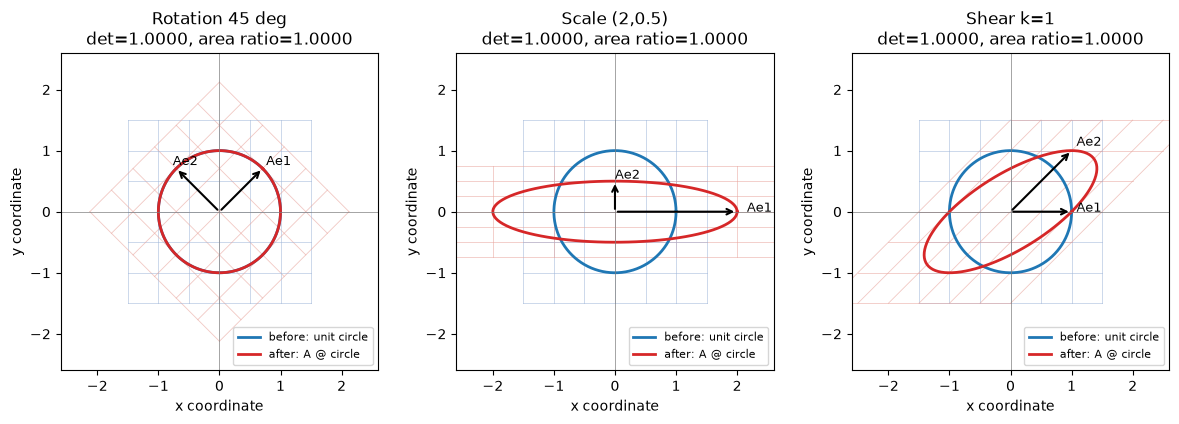

In [17]:
from src import linear_algebra as la

points = la.unit_circle()
transforms = [("Rotation 45 deg",la.rotation_matrix(np.pi/4)),
              ("Scale (2,0.5)",la.scaling_matrix(2,0.5)), ("Shear k=1",la.shear_matrix(1.))]
fig, axes = plt.subplots(1,3,figsize=(12,4))
for ax, (title, transform) in zip(axes, transforms):
    moved = transform @ points
    np.testing.assert_allclose(moved[:,0], transform @ points[:,0])
    np.testing.assert_allclose(moved, la.transform_points(transform,points))
    check = la.area_ratio_check(transform,points)
    np.testing.assert_allclose(check["area_ratio"],abs(check["det"]),atol=1e-12)
    la.plot_transformation(transform,title,ax,points)
    ax.set(xlabel="x coordinate",ylabel="y coordinate")
print("점 배열의 shape:", points.shape)
general = np.array([[2.,1.],[1.,3.]])
check = la.area_ratio_check(general,points)
print("일반 행렬 det / 면적비:", check["det"],check["area_ratio"])
np.testing.assert_allclose(check["area_ratio"],5.)
fig.tight_layout()
plt.show()

### Power Iteration — 첫 곱셈·정규화에서 수렴까지

벡터에 A를 반복해 곱하고 길이를 1로 돌린다. 크기 폭주를 막으면서 지배 방향을 찾는다.
아래 첫 두 스텝은 설명용 시작 `[1,0]`이며 기존 보고서의 seed=42 시작과 다른 실험이다.
고유벡터 부호는 반대여도 같은 축이다. 결과는 잔차 `||Av-λv||`와
검증 전용 `np.linalg.eig`를 사용하는 비교 함수로 확인한다.

In [18]:
A = np.array([[4.,1.],[1.,3.]])
direction = np.array([1.,0.])
for step in range(1,3):
    multiplied = A @ direction
    length = np.linalg.norm(multiplied)
    direction = multiplied/length
    estimate = direction @ A @ direction
    print("step",step,"곱",multiplied,"길이",length,"새 방향",direction,"λ 추정",estimate)
result = la.power_iteration(A,x0=np.array([1.,0.]))
eigenvalue = result["eigenvalue"]
eigenvector = result["eigenvector"]
residual = np.linalg.norm(A@eigenvector-eigenvalue*eigenvector)
reference = la.compare_with_numpy_eig(A,result)
print("수렴 / 반복 / λ / 잔차:",result["converged"],result["iterations"],eigenvalue,residual)
np.testing.assert_allclose(eigenvalue,reference["eigenvalue"],atol=1e-8)
assert result["converged"] and residual < 1e-5

step 1 곱 [4. 1.] 길이 4.123105625617661 새 방향 [0.970143 0.242536] λ 추정 4.411764705882353
step 2 곱 [4.123106 1.697749] 길이 4.45896321370523 새 방향 [0.924678 0.38075 ] λ 추정 4.559171597633135
수렴 / 반복 / λ / 잔차: True 21 4.618033988749177 1.2663230153200258e-06


### SVD — 세 배열에서 이미지를 다시 만들기

먼저 2×2 행렬의 k=1 근사를 직접 만든다. `S`는 대각 행렬이 아니라 특이값 벡터다.
`U[:,:k] * S[:k]`는 U의 각 열에 해당 특이값을 곱하고, `@ Vt[:k,:]`가 원래 크기로 되돌린다.
이후 기존 입력의 k=10·50·100 결과를 같은 밝기 범위로 비교한다.
에너지는 픽셀 제곱합의 비율이고, 저장 비율은 **실수 개수** 기준이며 PNG 파일 크기가 아니다.

모듈의 상대 오차·에너지는 픽셀 범위를 자르기 전 근사로 계산한다. 표시용 복원은 0–1로 자르고 PSNR은 그 복원과 원본을 비교한다.

U / S / Vt shapes: (2, 2) (2,) (2, 2)
특이값: [0.9 0.3] k=1 복원:
 [[0.9 0. ]
 [0.  0. ]]
k 10 저장 비율 0.1568603515625 에너지 0.95410495513195 상대 오차 0.2142312882565231 PSNR(dB) 20.894644282219737
k 50 저장 비율 0.7843017578125 에너지 0.9977134766491302 상대 오차 0.04781760503067347 PSNR(dB) 33.841112262761364
k 100 저장 비율 1.568603515625 에너지 0.9999803347857739 상대 오차 0.004434547804005147 PSNR(dB) 54.45040054364632


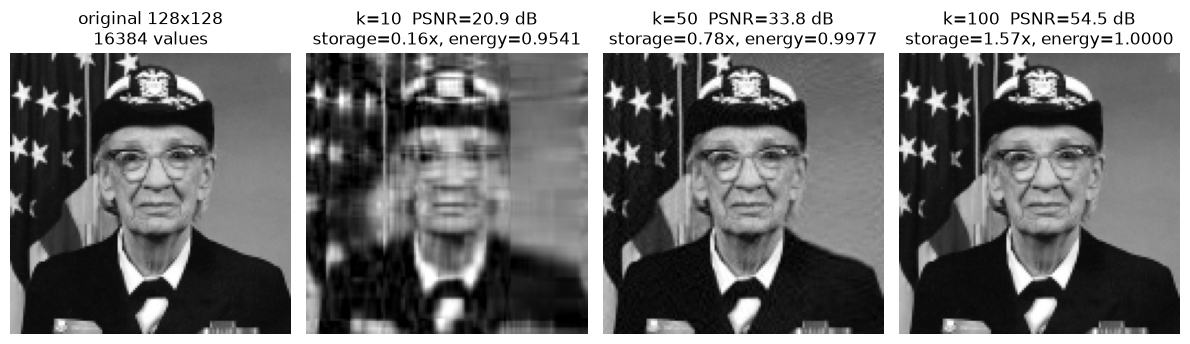

In [19]:
small_image = np.array([[0.9,0.],[0.,0.3]])
U,S,Vt = np.linalg.svd(small_image,full_matrices=False)
k = 1
small_approx = (U[:,:k]*S[:k])@Vt[:k,:]
small_result = la.svd_compress(small_image,k)
print("U / S / Vt shapes:",U.shape,S.shape,Vt.shape)
print("특이값:",S,"k=1 복원:\n",small_approx)
np.testing.assert_allclose(small_approx,small_result["reconstruction"])
np.testing.assert_allclose(small_result["energy_retained"],0.9)
np.testing.assert_allclose(small_result["relative_error"],1/np.sqrt(10))

# Matplotlib으로 읽은 PNG를 기존 실험과 같은 밝기 배열로 변환한다.
image = plt.imread(ROOT/"data/grace_hopper_128.png")
if image.ndim == 3:
    image = image[...,:3] @ np.array([0.299,0.587,0.114])
image = np.asarray(image,dtype=float)
fig,axes = plt.subplots(1,4,figsize=(12,3.5))
svd_results = la.plot_svd_compression(image,axes=axes)
for item in svd_results:
    print("k",item["k"],"저장 비율",item["storage_ratio"],"에너지",item["energy_retained"],
          "상대 오차",item["relative_error"],"PSNR(dB)",item["psnr_db"])
assert svd_results[0]["relative_error"] > svd_results[1]["relative_error"] > svd_results[2]["relative_error"]
assert svd_results[2]["storage_ratio"] > 1
fig.tight_layout()
plt.show()

## 기본 시연 마무리와 다음 단계

1. `W1`의 두 번째 열 기울기가 0인 이유를 입력과 연결해 설명해 보자.
2. 첫 갱신과 20회 갱신의 가중치를 구분하고, `forward`의 반환 사전과 객체 상태를 설명해 보자.
3. Momentum의 이점이 학습률에 따라 달라지는 이유를 경로와 연결해 보자.
4. SVD의 k가 커질 때 화질과 저장량이 각각 어떻게 달라지는가?

<details><summary>확인할 핵심</summary>
입력 x[1]=0이라 해당 연결의 이번 기울기가 0이다. `forward`·`backward`는 가중치를 바꾸지 않고
`sgd_step`이 바꾼다. 이 노트북의 학습 셀은 매번 새 객체로 시작한다. 모듈 검산 셀도
`example_network()`를 다시 부르므로 재실행하면 초기 기울기로 돌아간다.
Momentum은 과거 속도를 누적하며 언제나 GD보다 빠르지는 않다. SVD의 k를 키우면
근사 오차는 줄지만 저장할 실수 수가 늘어 원본보다 많아질 수도 있다.
</details>

다음 [확률과 손실 노트북](probability_loss.ipynb)에서 BCE를 왜 쓰는지 확률 가정으로 연결한다.
Adam·Newton Method는 선택 확장이며 `src/optimizer.py`와 HTML 보조 자료에서 이어 읽는다.